In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from scipy import stats

# Okabe-Ito colours [12]: easy to tell apart, also for people with colour blindness.
# Yellow is left out, because it is hard to see on a white background.
OKABE_ITO = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00", "#CC79A7"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OKABE_ITO)

# EU Tech Job Market
## What happened to tech jobs in Europe since 2020, and what do they pay?

### Abstract

_TODO: write at the end, when the results are ready._

### Table of Contents

* [1. Problem formulation](#chapter1)
* [2. Data sources](#chapter2)
* [3. Validation and cleaning](#chapter3)
* [4. Consolidation](#chapter4)
* [5. Statistical methods](#chapter5)
* [6. Demand for tech jobs](#chapter6)
* [7. Roles and languages](#chapter7)
* [8. Pay, shortage and remote work](#chapter8)
* [9. Comparison with a forecast](#chapter9)
* [10. Limitations](#chapter10)
* [11. Conclusion](#chapter11)
* [12. References](#chapter12)

### 1. Problem formulation <a class="anchor" id="chapter1"></a>

Tech jobs are often called "the jobs of the future". But since 2022 I have also read many news stories about layoffs and about fewer job ads for developers. Both stories may be true at the same time if they measure different things. This matters for everyone who works in IT or wants to start: it affects which skills to learn, where to look for work and what salary to expect.

The main question of this project is:

> **What happened to the tech job market in Europe between 2020 and 2026, and how does it look today?**

#### 1.1. Why one data source is not enough <a class="anchor" id="section_1_1"></a>

The job market has several sides, and each public source shows only one of them:

| View | Source | What it shows | What it cannot show |
|---|---|---|---|
| Demand | Indeed job postings [1] | How the number of job ads changes, every day | How many people work in IT; salaries |
| Supply | Eurostat employment statistics [3] | How many ICT specialists work in each country | Which roles; pay; only one value per year |
| Shortage | Eurostat enterprise survey [4] | Share of firms that could not fill ICT jobs | Which roles; only every second year since 2020 |
| People | Stack Overflow Developer Survey [2] | Roles, salaries, remote work, languages, AI use | Only people who answered; not a random sample |
| Skills | GitHub Innovation Graph [7] | Which programming languages people push code in | Anything about jobs or pay |

Each of these organizations publishes analyses based only on its own data: Indeed Hiring Lab writes about job postings [1], Eurostat about employment [3], [4] and Stack Overflow about its survey [2]. In this project I put the sources together. The goal is to see if they tell the same story, and to explain it when they do not.

#### 1.2. Research questions <a class="anchor" id="section_1_2"></a>

| # | Question | Data | Method |
|---|---|---|---|
| Q1 | How did job postings for tech roles change since 2020, compared with all job postings? | Indeed (DE, FR, GB) | Index comparison (descriptive) |
| Q2 | Does the number of people in ICT jobs move in the same direction as the job ads? | Eurostat + Indeed (DE, FR) | Merge by country and year (descriptive) |
| Q3 | Did the mix of developer roles change between 2023 and 2026? | Stack Overflow | Chi-square test, **H3** |
| Q4 | Do some role groups earn more than others, after adjusting for price levels? | Stack Overflow + Eurostat | Kruskal–Wallis test, **H4** |
| Q5 | Did remote work become less common between 2022 and 2024? | Stack Overflow | Chi-square test, **H5** |
| Q6 | Do countries with a stronger ICT shortage pay developers more? | Eurostat + Stack Overflow | Spearman correlation, **H6** |
| Q7 | Do GitHub and the survey agree on the most used languages? | GitHub + Stack Overflow | Spearman correlation (exploratory) |
| Q8 | Do the findings agree with a published forecast for 2030? | WEF Future of Jobs Report 2025 [8] | Comparison (qualitative) |

Q1, Q2, Q7 and Q8 describe the data. Q3–Q6 are formal tests with hypotheses that I fixed in advance (section 1.3).

#### 1.3. Hypotheses and rules fixed before the analysis <a class="anchor" id="section_1_3"></a>

If we look at the data first and choose the test later, it is easy to find a "significant" result by chance. This is called p-hacking. To avoid it, I wrote down all tests and rules below **before** running any analysis. This text was committed to Git before the analysis code, so the commit history shows the order.

**H3 (roles).** Let $p_g^{(t)}$ be the share of respondents in role group $g$ in survey year $t$:

$$H_0: \; p_g^{(2023)} = p_g^{(2026)} \;\text{ for every group } g \qquad H_1: \; \text{at least one share is different} \tag{1}$$

**H4 (pay).** Let $F_g$ be the distribution of real yearly pay (formula (4) below) in role group $g$, in the 2025 survey:

$$H_0: \; F_1 = F_2 = \dots = F_k \qquad H_1: \; \text{at least one group tends to earn more or less} \tag{2}$$

**H5 (remote work).** The shares of *Remote*, *Hybrid* and *In-person* answers are the same in 2022 and in 2024 ($H_0$), or they are different ($H_1$). In 2022 two of the answers had other names ("Fully remote", "Full in-person"), but the meaning is the same.

**H6 (shortage and pay).** Let $\rho_s$ be the Spearman correlation across countries between the share of firms with hard-to-fill ICT vacancies (Eurostat, 2024) and the median real pay of developers (Stack Overflow, 2024):

$$H_0: \; \rho_s = 0 \qquad H_1: \; \rho_s \neq 0 \tag{3}$$

With the 2024 data, 24 countries meet both conditions (at least 30 pay answers and a Eurostat value). With so few points, only a strong correlation ($|\rho_s|$ above about 0.40) can be significant. So a non-significant result will mean "no clear evidence", not "no relation".

**Rules for all tests:**

* Significance level $\alpha = 0.05$. H3–H6 are four tests, so the p-values are corrected with the Holm method [9].
* Every test also reports an effect size, because with thousands of answers even a very small difference can be "significant".
* A group or a country takes part in a test only if it has **at least 30 answers**.
* Bootstrap confidence intervals use 10 000 resamples with a fixed random seed (42), so the numbers are the same on every run.
* Role groups: *Software development*, *Data & AI*, *Cloud & operations*, *Security*, *Architecture & management*, *Other*. Students and retired people are not counted. The exact mapping of every survey answer is shown in section 4.

**Rules for pay (H4 and H6):**

* Only employees are counted: "Employed, full-time" in 2022–2024 and "Employed" in 2025–2026 (from 2025 the survey no longer separates full-time and part-time). Freelancers are left out, because their income is not comparable with a salary.
* Answers without pay or with pay of 0 are removed. After that, the lowest 1% and the highest 1% of each survey year are removed as likely input errors.
* Pay is made comparable between countries with the Eurostat price level index $PLI$ (EU27 = 100) for actual individual consumption:

$$w_{\text{real}} = \frac{w_{\text{USD}} \,/\, r_t}{PLI_{c,t} \,/\, 100} \tag{4}$$

Where:
* $w_{\text{USD}}$ is the yearly pay in US dollars from the survey (`ConvertedCompYearly`),
* $r_t$ is the average number of US dollars for 1 euro in year $t$ [6],
* $PLI_{c,t}$ is the price level index of country $c$ in year $t$ [5]. A value of 60 means that prices are 40% lower than the EU average.

The 2026 survey is used with the 2025 values of $r_t$ and $PLI$, because 2026 values are not published yet.

#### 1.4. Scope and assumptions <a class="anchor" id="section_1_4"></a>

* **Europe** means 31 countries: the EU27, the United Kingdom, Switzerland, Norway and Iceland. Some sources cover only some of them; each section says which countries it uses.
* **Time:** from February 2020 (the start of the Indeed data) to November 2026. The survey years are 2022–2026, because older surveys ask about roles and remote work in a different way.
* **The Indeed numbers are an index, not counts.** Each series is a seasonally adjusted 7-day average that equals 100 on 1 February 2020. A value of 50 means half as many postings as on that day [1]. So we can compare *changes* between sectors, but not their sizes.
* **The sources cover different years.** Indeed goes to November 2026 and the survey to 2026. Employment and price levels end in 2025, and hard-to-fill vacancies exist only for 2020, 2022 and 2024. Each question uses only the years that its data has.
* **The survey gets smaller.** The number of European respondents fell from 38 050 in 2023 to 9 356 in 2026. Fewer answers do not mean fewer jobs. The group of people who answer can also change from year to year, so comparisons between years describe the respondents, not the whole market.
* **Stock and flow are different things.** Eurostat counts people who *have* an ICT job (stock). Indeed counts *open* jobs (flow). The two can move in different directions.
* **The survey is not a random sample** of all developers. People decide themselves if they answer, so the results describe the people who answered, not all developers.
* **This is not a forecast.** The data shows what happened until today. In section 9 I compare it with a published forecast, but I do not make my own predictions.

#### 1.5. Biases I watch for <a class="anchor" id="section_1_5"></a>

A data project can go wrong not only because of bad data, but also because of the way people think. The table shows the cognitive biases [11] that are most likely to affect this project, plus two common statistical traps, and what I do against each of them.

| Bias | How it could affect this project | What I do |
|---|---|---|
| Confirmation bias | I expect bad news for tech jobs, so I might notice only the results that agree | Tests and rules are fixed in advance (section 1.3), and results that do not fit are reported as well |
| Availability heuristic | News about layoffs is easy to remember, but it is not data | The question is answered with four data sources, not with news |
| Anchoring and framing | "Half of the peak" and "close to the 2020 level" can describe the same number | Changes are measured against one base, 1 February 2020. When I describe a fall from a peak, I also give the level compared with 2020 |
| Survivorship bias | People who left IT are probably less likely to answer a developer survey | Survey results describe the respondents only (section 1.4) |
| Clustering illusion | It is easy to see a pattern in a noisy line or in a few points | Correlations are tested, not judged by eye. Highest and lowest points use monthly means, not single days |
| Authority bias | A forecast from a famous organization is easy to accept as fact | The WEF forecast is treated as the opinion of the employers it surveyed (section 9) |
| Automation bias | Code, and the AI tools I used, can give a wrong answer that looks right | Important steps have checks (`assert`), and every number in the text comes from a printed output |
| Declinism | Seeing every change as a decline | Growth is reported as clearly as decline |
| Gambler's fallacy | After years of decline it is tempting to say "now it must go up" | No predictions of my own (section 1.4) |
| Halo effect | Big, well-known sources look correct by default | Every source is checked before use (sections 2–3) |
| Curse of knowledge | Terms like "index" or "price level" are clear to me, but maybe not to the reader | Each term is explained when it is first used |
| Blind spot bias | Believing that this list makes me free of bias | The plan, the code and the data were also checked in a separate review |
| Simpson's paradox | A pay difference between role groups can come from a different mix of countries | The pay comparison is repeated inside one country, Germany, as an extra check |
| Ecological fallacy | A link between countries (H6) says nothing about single people | H6 is interpreted only at country level |

### 2. Data sources <a class="anchor" id="chapter2"></a>

In this section I load every file of the snapshot and look at it before any cleaning: how big it is, which years and countries it covers, and what looks strange. Here I only write the problems down. The fixes come in section 3.

All files are in the `data/` folder. How they were made is described in `data/SOURCES.md`. All plots use the Okabe–Ito colours [12], which people with colour blindness can also tell apart.

In [2]:
DATA_DIR = Path("data")
SURVEY_YEARS = [2022, 2023, 2024, 2025, 2026]


def overview(table):
    """Type, number of missing values, number of different values and one example for every column."""
    return pd.DataFrame({
        "type": table.dtypes.astype(str),
        "missing": table.isna().sum(),
        "unique": table.nunique(),
        "example": table.iloc[0],
    })

#### 2.1. Indeed job postings <a class="anchor" id="section_2_1"></a>

There are two tables. The first one has one index value per day for each of seven countries (*country totals*). The second one has one value per day for each sector in Germany, France and the United Kingdom. As explained in section 1.4, every series equals 100 on 1 February 2020 [1].

In [3]:
indeed_sectors = pd.read_csv(DATA_DIR / "indeed_sectors.csv.gz", parse_dates=["date"])
indeed_totals = pd.read_csv(DATA_DIR / "indeed_totals.csv.gz", parse_dates=["date"])
sector_examples = pd.read_csv(DATA_DIR / "indeed_sector_examples.csv")

print("Sector table:", indeed_sectors.shape, "| country totals:", indeed_totals.shape)
print("Days:", indeed_totals["date"].min().date(), "to", indeed_totals["date"].max().date())
overview(indeed_totals)

Sector table: (317184, 4) | country totals: (17346, 4)
Days: 2020-02-01 to 2026-11-13


,type,missing,unique,example
date,datetime64[us],0,2478,2020-02-01 00:00:00
jobcountry,str,0,7,DE
indeed_job_postings_index_SA,float64,0,9751,100.0
indeed_job_postings_index_NSA,float64,0,10010,100.0


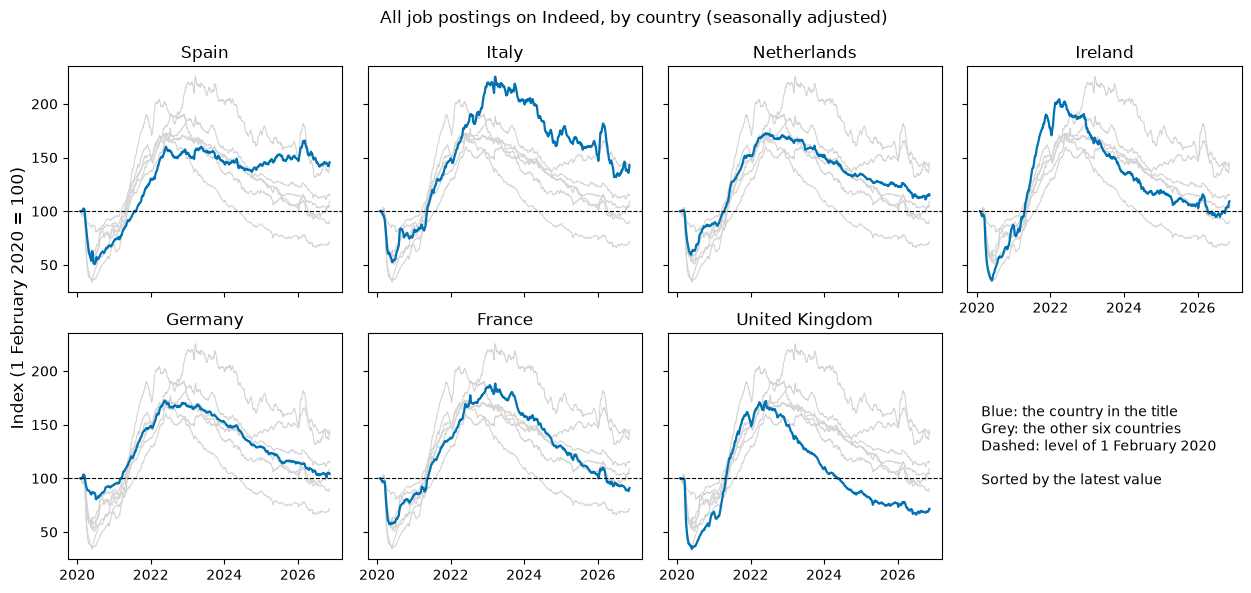

,lowest month,lowest,highest month,highest,highest before 2024,on 2026-11-13
jobcountry,,,,,,
ES,2020-06,53.9,2026-03,162.6,159.1,145.5
IT,2020-06,54.1,2023-01,218.9,218.9,142.8
NL,2020-05,61.1,2022-06,172.1,172.1,114.9
IE,2020-05,38.0,2022-03,202.1,202.1,109.2
DE,2020-07,81.9,2022-05,171.2,171.2,104.1
FR,2020-05,57.7,2023-01,185.4,185.4,90.9
GB,2020-06,36.3,2022-05,167.6,167.6,71.7


In [4]:
COUNTRY_NAMES = {"DE": "Germany", "ES": "Spain", "FR": "France", "GB": "United Kingdom",
                 "IE": "Ireland", "IT": "Italy", "NL": "Netherlands"}
index = indeed_totals.pivot(index="date", columns="jobcountry", values="indeed_job_postings_index_SA")
order = index.iloc[-1].sort_values(ascending=False).index  # countries sorted by their latest value

# one small plot per country: the country in blue, the other six in grey for comparison
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, country in zip(axes.flat, order):
    for other in index.columns.drop(country):
        ax.plot(index.index, index[other], color="lightgray", linewidth=0.8)
    ax.plot(index.index, index[country], color="#0072B2", linewidth=1.6)
    ax.axhline(100, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(COUNTRY_NAMES[country])
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# the last plot in the top row has no plot below it, so it needs its own year labels
axes[0, -1].tick_params(labelbottom=True)

legend_box = axes.flat[-1]
legend_box.axis("off")
legend_box.text(0.05, 0.5, "Blue: the country in the title\nGrey: the other six countries\nDashed: level of 1 February 2020\n\nSorted by the latest value",
                va="center", fontsize=10, transform=legend_box.transAxes)
fig.suptitle("All job postings on Indeed, by country (seasonally adjusted)")
fig.supylabel("Index (1 February 2020 = 100)")
fig.tight_layout()
plt.show()

# monthly means, so that one unusual day cannot decide the lowest or the highest point
monthly = index.resample("MS").mean()
pd.DataFrame({
    "lowest month": monthly.idxmin().dt.strftime("%Y-%m"),
    "lowest": monthly.min(),
    "highest month": monthly.idxmax().dt.strftime("%Y-%m"),
    "highest": monthly.max(),
    "highest before 2024": monthly.loc[:"2023"].max(),
    f"on {index.index.max().date()}": index.iloc[-1],
}).round(1).loc[order]

All seven countries follow a similar path. Job postings dropped sharply at the start of the COVID-19 pandemic: in every country the lowest month is between May and July 2020. Then they grew fast. Most countries had their highest month in 2022, France and Italy in January 2023. After that the index went down again. Spain is different: its highest month is March 2026 (162.6), but this is only a little above its level before 2024 (159.1).

The table uses monthly means, so that one unusual day cannot decide the lowest or the highest point.

On 13 November 2026, the United Kingdom (71.7) and France (90.9) are below the level of February 2020, while Spain (145.5) and Italy (142.8) are still far above it. These numbers are for **all** jobs; tech jobs follow in section 6.

Next, the sector table:

In [5]:
sectors_per_country = indeed_sectors.groupby("jobcountry")["display_name"].nunique()
print("Sectors per country:", sectors_per_country.to_dict())
print("Different sectors in all three countries:", indeed_sectors["display_name"].nunique())
print("Missing values in the sector table:", indeed_sectors.isna().sum().sum())

data_sectors = set(indeed_sectors["display_name"])
example_sectors = set(sector_examples["sector"])
print("Sectors in the data, but not in the example file:", sorted(data_sectors - example_sectors))
print("Sectors in the example file, but not in the data:", sorted(example_sectors - data_sectors))

Sectors per country: {'DE': 45, 'FR': 34, 'GB': 49}
Different sectors in all three countries: 52
Missing values in the sector table: 0
Sectors in the data, but not in the example file: ['Agriculture & Forestry', 'Chemical Engineering', 'Data & Analytics', 'IT Infrastructure, Operations & Support', 'IT Systems & Solutions', 'Mechanical Engineering', 'Real Estate', 'Social Science']
Sectors in the example file, but not in the data: ['IT Operations & Helpdesk', 'Information Design & Documentation', 'Mathematics']


Observations:

* Each country has its own list of sectors: 45 in Germany, 34 in France and 49 in the United Kingdom, 52 different names in total. So not every sector can be compared in all three countries.
* The file with example job titles does not match the data. Eight sectors have no examples, among them *Data & Analytics* and both *IT* sectors, and three sectors from the file do not appear in the data. It seems the file was not updated when the sectors changed. I use it only to understand what a sector means, never in a calculation.
* Neither table has missing values. The last day is 13 November 2026.
* Each country is compared with **its own** level in February 2020. A higher line means faster growth since then, not more jobs: the plot cannot tell us if Italy has more job ads than Germany.
* Indeed is one job site. The index shows how postings on Indeed change, not the total number of job ads in a country.

#### 2.2. Eurostat <a class="anchor" id="section_2_2"></a>

Eurostat gives four tables. Three of them have one value per country and year; the exchange rate table has one value per year. In all of them, `OBS_VALUE` is the number and `OBS_FLAG` is a note about its quality.

In [6]:
eurostat_files = {
    "ICT specialists": "eurostat_ict_specialists.csv",
    "ICT vacancies": "eurostat_ict_vacancies.csv",
    "Price levels": "eurostat_price_levels.csv",
    "USD rates": "eurostat_usd_rates.csv",
}
eurostat = {name: pd.read_csv(DATA_DIR / file) for name, file in eurostat_files.items()}


def eurostat_summary(table):
    """Rows, years, countries, missing values and flagged values of one Eurostat table."""
    countries = table.loc[table["geo"] != "EU27_2020", "geo"].nunique() if "geo" in table else "-"
    return {
        "rows": len(table),
        "years": f"{table['TIME_PERIOD'].min()}-{table['TIME_PERIOD'].max()}",
        "countries": countries,
        "missing values": table["OBS_VALUE"].isna().sum(),
        "flagged values": table["OBS_FLAG"].notna().sum(),
    }


pd.DataFrame({name: eurostat_summary(table) for name, table in eurostat.items()}).T

,rows,years,countries,missing values,flagged values
ICT specialists,1336,2004-2025,31,0,874
ICT vacancies,3779,2012-2024,30,39,67
Price levels,992,1995-2025,31,0,0
USD rates,55,1971-2025,-,0,0


In [7]:
all_flags = pd.concat(table["OBS_FLAG"] for table in eurostat.values()).dropna()
all_flags.value_counts().rename("values with this flag")

OBS_FLAG
e     586
be    166
b     126
u      41
d      16
bd      4
bu      2
Name: values with this flag, dtype: int64

A flag has one or more letters. Their meaning, from the official Eurostat list [10]:

| Letter | Meaning |
|---|---|
| b | break in time series: the method changed, so values before and after the break are not fully comparable |
| d | definition differs (see the metadata of the dataset) |
| e | estimated |
| u | low reliability |

Most flags are in the employment table: 874 of its 1336 values. The most common flag is *e*, so many of these numbers are estimates. For this project the *b* flags matter most, because a jump in a year with a break can come from a new method and not from a real change. Section 3 deals with this.

In [8]:
specialists = eurostat["ICT specialists"]
print("Last year for the United Kingdom:", specialists.loc[specialists["geo"] == "UK", "TIME_PERIOD"].max())

vacancies = eurostat["ICT vacancies"]
print("Years with vacancy data:", sorted(vacancies["TIME_PERIOD"].unique().tolist()))

# share of recruiting firms that had hard-to-fill ICT vacancies
hard_to_fill = vacancies[(vacancies["indic_is"] == "E_ITSPVAC2") & (vacancies["unit"] == "PC_ENT_ITSPRCR2")]
hard_to_fill_2024 = hard_to_fill[(hard_to_fill["TIME_PERIOD"] == 2024) & (hard_to_fill["geo"] != "EU27_2020")]
print("Countries with a 2024 value:", hard_to_fill_2024["OBS_VALUE"].notna().sum())
hard_to_fill_2024[hard_to_fill_2024["OBS_VALUE"].isna()][["geo", "OBS_VALUE", "OBS_FLAG"]]

Last year for the United Kingdom: 2019
Years with vacancy data: [2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2024]
Countries with a 2024 value: 27


,geo,OBS_VALUE,OBS_FLAG
2789,FR,NaN,u


Observations:

* The **United Kingdom** is in the employment table only until 2019, so for later years it cannot be linked to the other sources through Eurostat.
* The **vacancy table** has data only for some years, and since 2020 only for every second year (2020, 2022, 2024). Switzerland is missing completely, so this table has 30 countries instead of 31.
* For 2024, the share of firms with hard-to-fill ICT vacancies is known for 27 countries. Iceland and the United Kingdom have no row for 2024. France has a row, but no value: Eurostat marks it with *u* (low reliability) and does not publish the number.
* Price levels and exchange rates have no missing values and no flags. Both end in 2025.

#### 2.3. Stack Overflow Developer Survey <a class="anchor" id="section_2_3"></a>

There is one file per survey year. It contains only European respondents and only the columns listed in `build_snapshot.py`. Each row is one person.

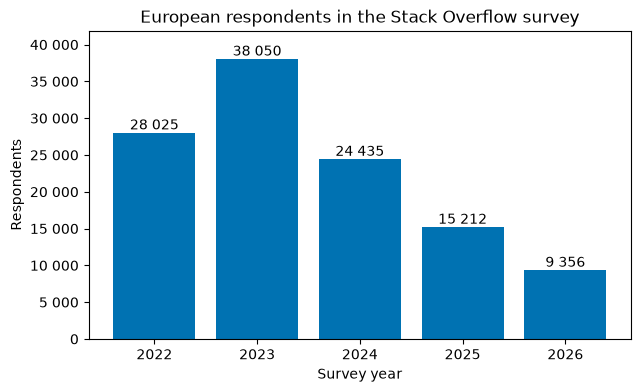

In [9]:
surveys = {year: pd.read_csv(DATA_DIR / f"stackoverflow_{year}.csv.gz", low_memory=False) for year in SURVEY_YEARS}

respondents = pd.Series({year: len(survey) for year, survey in surveys.items()})
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(respondents.index.astype(str), respondents.values, color="#0072B2")
ax.bar_label(bars, labels=[f"{value:,}".replace(",", " ") for value in respondents])
ax.set(title="European respondents in the Stack Overflow survey", xlabel="Survey year", ylabel="Respondents",
       ylim=(0, respondents.max() * 1.1))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
plt.show()

In [10]:
all_columns = sorted(set().union(*(survey.columns for survey in surveys.values())))
pd.DataFrame({year: ["yes" if column in survey else "-" for column in all_columns]
              for year, survey in surveys.items()}, index=all_columns)

,2022,2023,2024,2025,2026
AISelect,-,yes,yes,yes,yes
Age,yes,yes,yes,yes,yes
CompFreq,yes,-,-,-,-
CompTotal,yes,yes,yes,yes,-
ConvertedCompYearly,yes,yes,yes,yes,yes
Country,yes,yes,yes,yes,yes
Currency,yes,yes,yes,yes,yes
DevType,yes,yes,yes,yes,-
EdLevel,yes,yes,yes,yes,-
Education,-,-,-,-,yes


The number of European respondents changes a lot: 38 050 in 2023, but only 9 356 in 2026. As written in section 1.4, this tells us something about the survey, not about the number of jobs.

The table shows which of the 24 kept columns exist in each year. The survey changed over time:

* Some questions only got a new name in 2026: `DevType` → `Role`, `RemoteWork` → `WorkSetting`, `EdLevel` → `Education`, `LanguageHaveWorkedWith` → `LanguagesHaveWorkedWith`.
* Some questions were dropped: `CompFreq` after 2022, `YearsCodePro` after 2024, `MainBranch` and `CompTotal` after 2025.
* Some questions are new: `AISelect` and `Industry` exist from 2023.

A new name does not guarantee the same answer options. Those are checked in section 3.

In [11]:
country_counts = pd.DataFrame({year: survey["Country"].value_counts() for year, survey in surveys.items()})
country_counts = country_counts.fillna(0).astype(int).sort_values(2026, ascending=False)
print("Countries in every year:", (country_counts > 0).all(axis=1).sum())
country_counts.head(8)

Countries in every year: 31


,2022,2023,2024,2025,2026
Country,,,,,
Germany,5395,7328,4947,3025,1983
United Kingdom of Great Britain and Northern Ireland,4190,5552,3224,2042,1374
France,2328,2933,2110,1409,794
Netherlands,1555,2383,1449,867,577
Poland,1732,2435,1534,888,527
Italy,1514,1835,1341,835,482
Spain,1521,1834,1123,717,453
Sweden,1020,1641,1016,616,370


In [12]:
smallest = country_counts.tail(5)
pd.concat([country_counts.loc[["Bulgaria"]], smallest])

,2022,2023,2024,2025,2026
Country,,,,,
Bulgaria,364,482,319,244,133
Estonia,141,234,110,70,35
Luxembourg,56,72,40,23,21
Iceland,28,57,31,13,13
Cyprus,61,84,63,39,11
Malta,39,46,29,19,11


In [13]:
pay_share = pd.Series({year: survey["ConvertedCompYearly"].notna().mean() for year, survey in surveys.items()})
print("Share of respondents who gave their pay:", (pay_share * 100).round(1).to_dict())

Share of respondents who gave their pay: {2022: 57.8, 2023: 57.5, 2024: 42.1, 2025: 71.7, 2026: 67.7}


Observations:

* All 31 countries appear in every survey year. Germany, the United Kingdom and France give the most answers.
* Small countries have very few answers. In 2026, Cyprus and Malta have 11 respondents each, and Bulgaria has 133. This is why every test needs at least 30 answers per group (section 1.3).
* The share of people who gave their pay changes from year to year, from 42.1% in 2024 to 71.7% in 2025. So the pay data is incomplete, and people who answer this question may differ from those who skip it.

#### 2.4. GitHub Innovation Graph <a class="anchor" id="section_2_4"></a>

For every country, quarter and language, `num_pushers` is the number of unique developers who made at least one git push to a repository in that language during the quarter [7].

In [14]:
# keep_default_na=False, because pandas would read the code "NA" (Namibia) as a missing value
languages = pd.read_csv(DATA_DIR / "github_languages.csv.gz", keep_default_na=False)
quarters = languages[["year", "quarter"]].drop_duplicates()
print("Quarters:", len(quarters), "| first:", tuple(quarters.iloc[0]), "| last:", tuple(quarters.iloc[-1]))
print("Countries:", languages["iso2_code"].nunique(), "| languages:", languages["language"].nunique())
print("Smallest number of developers in a row:", languages["num_pushers"].min())
overview(languages)

Quarters: 26 | first: (2020, 1) | last: (2026, 2)
Countries: 31 | languages: 295
Smallest number of developers in a row: 101


,type,missing,unique,example
num_pushers,int64,0,8519,6167
language,str,0,295,HTML
language_type,str,0,4,markup
iso2_code,str,0,31,AT
year,int64,0,7,2020
quarter,int64,0,4,1


In [15]:
last_quarter = languages[(languages["year"] == 2026) & (languages["quarter"] == 2)]
languages_per_country = last_quarter.groupby("iso2_code")["language"].nunique().sort_values()
print("Languages per country in 2026 Q2, fewest:", languages_per_country.head(4).to_dict())
print("Languages per country in 2026 Q2, most:", languages_per_country.tail(4).to_dict())

Languages per country in 2026 Q2, fewest: {'MT': 18, 'IS': 20, 'LU': 26, 'CY': 34}
Languages per country in 2026 Q2, most: {'NL': 169, 'FR': 196, 'GB': 213, 'DE': 242}


Observations:

* The table covers 26 quarters, from the first quarter of 2020 to the second quarter of 2026, and all 31 countries.
* The smallest value is 101. GitHub does not publish some numbers when fewer than 100 developers are behind them, to protect their privacy [7]. So a language used by only a few developers in a country is missing from the table, not zero.
* Because of this, small countries have short lists. In the second quarter of 2026, Malta has 18 languages and Germany 242. Comparisons between countries must take this into account.
* Besides programming languages, the table also counts markup and data formats such as HTML (column `language_type`).

#### 2.5. Summary <a class="anchor" id="section_2_5"></a>

In [16]:
summary = pd.DataFrame(
    [
        ("Indeed totals", len(indeed_totals), "day", indeed_totals["jobcountry"].nunique(), "jobcountry"),
        ("Indeed sectors", len(indeed_sectors), "day", indeed_sectors["jobcountry"].nunique(), "jobcountry"),
        ("Eurostat", sum(len(table) for table in eurostat.values()), "year",
         specialists.loc[specialists["geo"] != "EU27_2020", "geo"].nunique(), "geo"),
        ("Stack Overflow", sum(len(survey) for survey in surveys.values()), "survey year",
         len(country_counts), "Country"),
        ("GitHub", len(languages), "quarter", languages["iso2_code"].nunique(), "iso2_code"),
    ],
    columns=["source", "rows", "time unit", "countries", "country column"],
).set_index("source")
summary

,rows,time unit,countries,country column
source,,,,
Indeed totals,17346,day,7,jobcountry
Indeed sectors,317184,day,3,jobcountry
Eurostat,6162,year,31,geo
Stack Overflow,115078,survey year,31,Country
GitHub,61449,quarter,31,iso2_code


The sources differ in almost everything: time unit (day, year, quarter), period and the way they name countries (`GB` and `UK`, `GR` and `EL`, or full names in the survey). To join them, I need one common key for countries and one for time. Section 4 builds both.

### 3. Validation and cleaning <a class="anchor" id="chapter3"></a>

_TODO_

### 4. Consolidation <a class="anchor" id="chapter4"></a>

_TODO_

### 5. Statistical methods <a class="anchor" id="chapter5"></a>

_TODO_

### 6. Demand for tech jobs <a class="anchor" id="chapter6"></a>

_TODO_

### 7. Roles and languages <a class="anchor" id="chapter7"></a>

_TODO_

### 8. Pay, shortage and remote work <a class="anchor" id="chapter8"></a>

_TODO_

### 9. Comparison with a forecast <a class="anchor" id="chapter9"></a>

_TODO_

### 10. Limitations <a class="anchor" id="chapter10"></a>

_TODO_

### 11. Conclusion <a class="anchor" id="chapter11"></a>

_TODO_

### 12. References <a class="anchor" id="chapter12"></a>

1. Indeed Hiring Lab. *Indeed Job Postings Index*. https://github.com/hiring-lab/job_postings_tracker (data under CC BY 4.0, commit `d876002`).
2. Stack Overflow. *Annual Developer Survey*, 2022–2026. https://survey.stackoverflow.co/ (data under ODbL 1.0).
3. Eurostat. *ICT specialists in employment*, dataset `isoc_sks_itspt`. https://ec.europa.eu/eurostat/statistics-explained/index.php/ICT_specialists_in_employment
4. Eurostat. *ICT specialists – statistics on hard-to-fill vacancies in enterprises*, dataset `isoc_ske_itrcrn2`. https://ec.europa.eu/eurostat/statistics-explained/index.php/ICT_specialists_-_statistics_on_hard-to-fill_vacancies_in_enterprises
5. Eurostat. *Purchasing power parities, price level indices, nominal and real expenditures (COICOP 2018)*, dataset `prc_ppp_ind_1`.
6. Eurostat. *Euro/ECU exchange rates – annual data*, dataset `ert_bil_eur_a`.
7. GitHub. *Innovation Graph*. https://github.com/github/innovationgraph (data under CC0 1.0, commit `db6ccdf`).
8. World Economic Forum (2025). *Future of Jobs Report 2025*. Insight Report, January 2025. https://www3.weforum.org/docs/WEF_Future_of_Jobs_Report_2025.pdf
9. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
10. Eurostat. *Observation status (flag) code list* `OBS_FLAG`. https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/codelist/ESTAT/OBS_FLAG
11. TitleMax. *50 Cognitive Biases to Be Aware Of So You Can Be the Very Best Version of You* (infographic). Shared in the SoftUni Data Science course materials.
12. Okabe, M. & Ito, K. (2008). *Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people*. https://jfly.uni-koeln.de/color/
